# Prediction of Oil Presence Using Machine Learning
### **SPE DSEATS Africa Region, Datathon 2026**

**Team:** GeoSpark



**SPE Section:** All members are in SPE Lagos Section 61.


The task was to investigate different geological and seismic measurements, and decide whether it holds oil (1) or not (0). We decided to approach it the way an exploration team would size up a
prospect, and then let the data confirm the consistency with subsurface physics.

The notebook is divided into four parts:
1. Exploratory data analysis (getting to know the data).
2. Part 1: A Standard Machine Learning Workflow.
3. Part 2: A Physics Informed Workflow.
4. A Comparison of the two approches on the datasets.

## How we thought about the problem

We approached this from the perspective of a petroleum system, and it lines up almost one to one with the columns we were given.

| Petroleum system element | Plain meaning | Column |
|---|---|---|
| Reservoir | A porous, permeable rock that can hold and flow oil | Rock_Type, Porosity, Permeability |
| Trap | A shape that stops the oil escaping | Trap_Type |
| Charge | A working source nearby that filled the trap | Proximity_to_Oil_Field |


Seismic_score was the quality of the seismic survey data for that location

Oil presence is the target variable and basically corresponds to if a location has oil(1) or not(0)




## 1. Setup and loading the data

In [ ]:
# We try to import each library and only install the ones that are missing,
# so the notebook runs the same way on our laptops and in a fresh Google Colab.
import importlib, subprocess, sys

def ensure(pkg, pip_name=None):
    try:
        importlib.import_module(pkg)
    except Exception:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg])

for pkg, pip_name in [("pandas", None), ("numpy", None), ("sklearn", "scikit-learn"),
                      ("matplotlib", None), ("seaborn", None), ("scipy", None),
                      ("lightgbm", None), ("shap", None)]:
    ensure(pkg, pip_name)

try:
    import xgboost
    HAS_XGB = True
except Exception:
    HAS_XGB = False

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "axes.titleweight": "bold"})

# A small colour scheme so the plots stay consistent. Green is oil, red is a dry hole.
GREEN = "#1b7837"
RED = "#b2182b"
BLUE = "#2166ac"
ROCK_COLOURS = {"Sandstone": "#e8a33d", "Limestone": "#5fa2ce", "Shale": "#7a6a53"}

os.makedirs("figures", exist_ok=True)

# In Colab, upload these two files first (Files panel) so the paths resolve.
train_raw = pd.read_csv("oil_presence_trainset.csv")
test_raw = pd.read_csv("oil_presence_testset.csv")

print("Train:", train_raw.shape)
print("Test :", test_raw.shape)
train_raw.head()

Train: (3000, 8)
Test : (2000, 7)


,Rock_Type,Porosity,Permeability,Trap_Type,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence
0,Limestone,17.667992,834.277472,NaN,0.705933,2.431355,2228.0,1
1,Limestone,27.665758,578.158034,NaN,0.545806,2.606158,1610.0,0
2,Sandstone,28.855946,404.790685,NaN,0.167530,1.143136,2344.0,0
3,Sandstone,0.410957,887.836673,Dome,0.026852,2.673532,NaN,0
4,Shale,16.490538,562.288802,NaN,NaN,2.064440,NaN,0


In [ ]:
# The competition brief gives a physical range for each measurement. We keep them. So, we can sanity check the values later.
PHYSICAL_RANGES = {
    "Porosity": (0, 30),                  # percent
    "Permeability": (1, 1000),            # millidarcies
    "Seismic_Score": (0, 1),              # score
    "Proximity_to_Oil_Field": (0, 5),     # km
    "Estimated_Reservoir_Depth": (500, 5000),  # metres
}

NUMERIC = list(PHYSICAL_RANGES)
CATEGORICAL = ["Rock_Type", "Trap_Type"]
TARGET = "Oil_Presence"

y = train_raw[TARGET].astype(int).values
has_seismic = train_raw["Seismic_Score"].notna().values   # the rows that look like the test set

print("Oil rate in training:", round(train_raw[TARGET].mean(), 3))
print("Missing values per column (train):")
print(train_raw.isna().sum())

Oil rate in training: 0.278
Missing values per column (train):
Rock_Type                       0
Porosity                      803
Permeability                 1186
Trap_Type                     767
Seismic_Score                1050
Proximity_to_Oil_Field        943
Estimated_Reservoir_Depth    1268
Oil_Presence                    0
dtype: int64


**A few things from this first look:**

1. The training data has a lot of missing values (some columns are about 40 percent empty), but the test data
   has no missing values in its numeric columns. So, handling missing values matter for training.
2. The word "None" in Trap_Type is read by pandas as a missing value, so "no trap" shows up as a
   blank in both files. We treat that as its own category rather than as missing data.
3. Only about 28 percent of locations have oil. Because of that, plain accuracy can be misleading. Therefore, a random guess of "dry" returns about 72% accuracy. So, we also track precision, recall, F1, ROC-AUC and PR-AUC.

## 2. Exploratory data analysis

We work through the data one question at a time and explain each plot as we go.

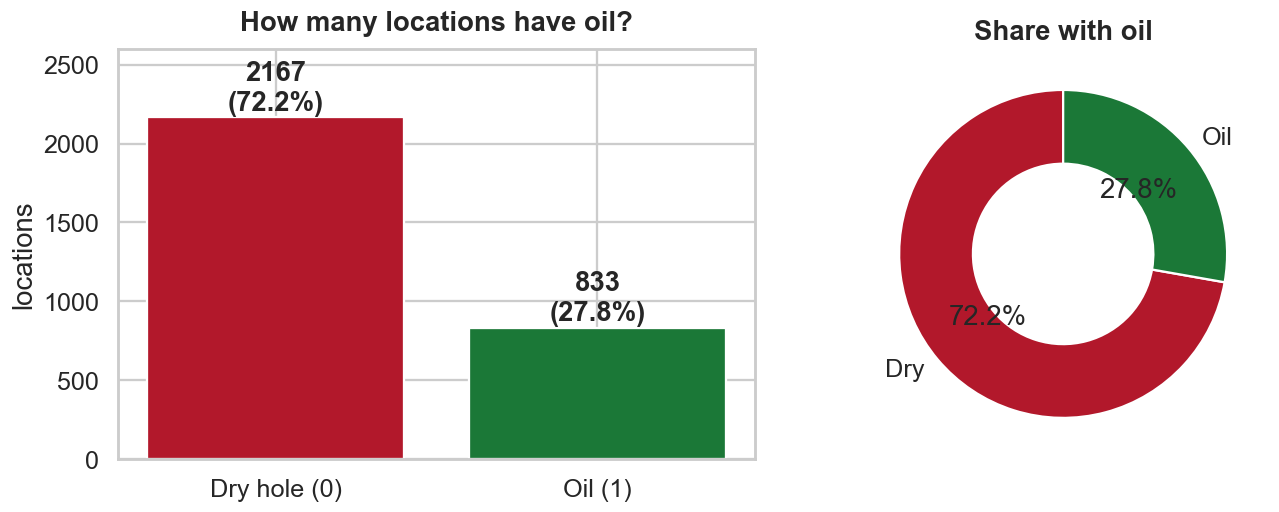

In [ ]:
# How often do we actually find oil?
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

counts = train_raw[TARGET].value_counts().sort_index()
ax[0].bar(["Dry hole (0)", "Oil (1)"], counts.values, color=[RED, GREEN])
ax[0].set_ylim(0, counts.max() * 1.20)
for i, v in enumerate(counts.values):
    ax[0].text(i, v + counts.max() * 0.02, f"{v}\n({v/len(train_raw):.1%})",
               ha="center", fontweight="bold")
ax[0].set_title("How many locations have oil?", pad=12)
ax[0].set_ylabel("locations")

ax[1].pie(counts.values, labels=["Dry", "Oil"], autopct="%1.1f%%", colors=[RED, GREEN],
          startangle=90, wedgeprops=dict(width=0.45, edgecolor="w"))
ax[1].set_title("Share with oil")

plt.tight_layout()
plt.savefig("figures/01_target_balance.png", bbox_inches="tight")
plt.show()

**Figure 1.** About one location in four has oil, indicating a class imbalance. This is an important caveat for the whole project.
A lazy model that predicts "dry" already returns about 72 percent accuracy. So, that is the threshold we tried to be cautious of, and why we never evaluated model performance on only accuracy.

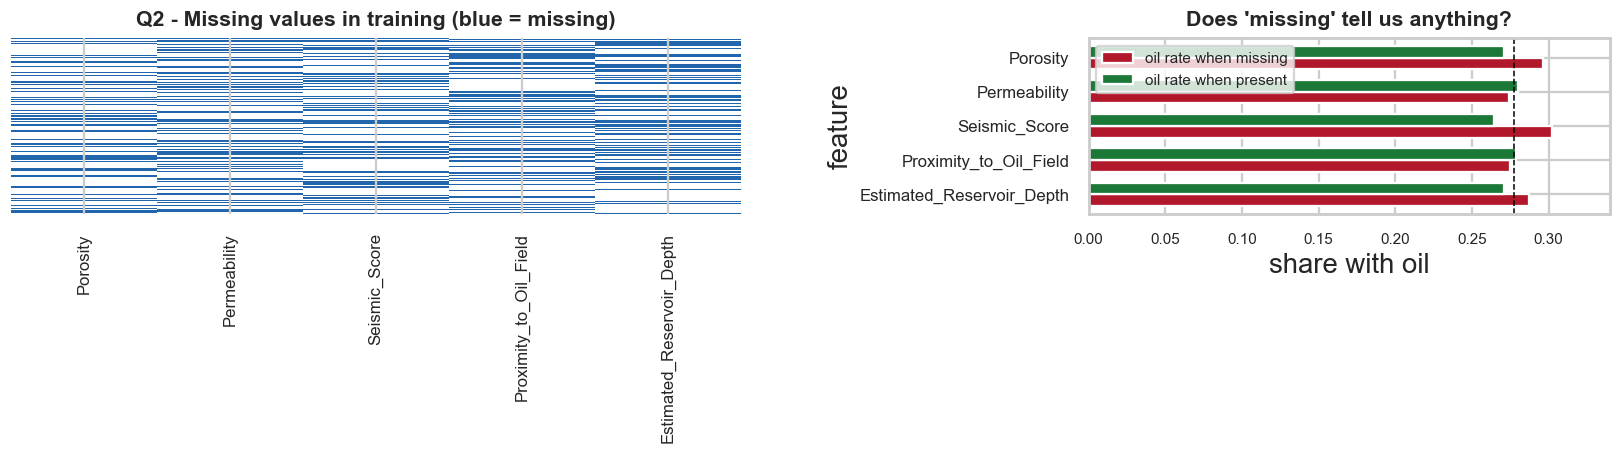

In [ ]:
# Where are the gaps, and does a missing value change the oil rate?
missing_cols = NUMERIC
missing_matrix = train_raw[missing_cols].isna().astype(int)

missing_signal = []
for col in missing_cols:
    is_missing = train_raw[col].isna()
    missing_signal.append({
        "feature": col,
        "oil rate when missing": train_raw.loc[is_missing, TARGET].mean(),
        "oil rate when present": train_raw.loc[~is_missing, TARGET].mean(),
        "missing_rows": int(is_missing.sum()),
    })
missing_signal = pd.DataFrame(missing_signal).set_index("feature")

fig = plt.figure(figsize=(15.8, 5.0))
axes = [
    fig.add_axes([0.04, 0.60, 0.42, 0.32]),
    fig.add_axes([0.66, 0.60, 0.30, 0.32]),
]

axes[0].imshow(missing_matrix.values, aspect="auto", interpolation="nearest",
               cmap=ListedColormap(["white", BLUE]))
axes[0].set_title("Q2 - Missing values in training (blue = missing)", fontsize=14, pad=8)
axes[0].set_xticks(np.arange(len(missing_cols)))
axes[0].set_xticklabels(missing_cols, rotation=90)
axes[0].tick_params(axis="x", labelsize=11)
axes[0].set_yticks([])
axes[0].set_xlabel("")
for spine in axes[0].spines.values():
    spine.set_visible(False)

plot_order = missing_signal.index[::-1]
ypos = np.arange(len(plot_order))
height = 0.34
axes[1].barh(
    ypos - height / 2,
    missing_signal.loc[plot_order, "oil rate when missing"],
    height=height,
    color=RED,
    label="oil rate when missing",
)
axes[1].barh(
    ypos + height / 2,
    missing_signal.loc[plot_order, "oil rate when present"],
    height=height,
    color=GREEN,
    label="oil rate when present",
)
axes[1].axvline(train_raw[TARGET].mean(), color="black", linestyle="--", linewidth=1)
axes[1].set_title("Does 'missing' tell us anything?", fontsize=14, pad=8)
axes[1].set_yticks(ypos)
axes[1].set_yticklabels(plot_order)
axes[1].set_ylabel("feature")
axes[1].set_xlabel("share with oil")
axes[1].set_xlim(0, 0.34)
axes[1].legend(loc="upper left", frameon=True, fontsize=10)
axes[1].tick_params(axis="y", labelsize=11)
axes[1].tick_params(axis="x", labelsize=10)

plt.savefig("figures/02_missingness.png", bbox_inches="tight")
plt.show()

**Figure 2.** The training file has many missingness, especially in the numerical columns, while the
test file is complete for the numerical measurements. That is why our imputation choices matter for
learning the model, but the final test predictions are not driven by filled-in numerical values.

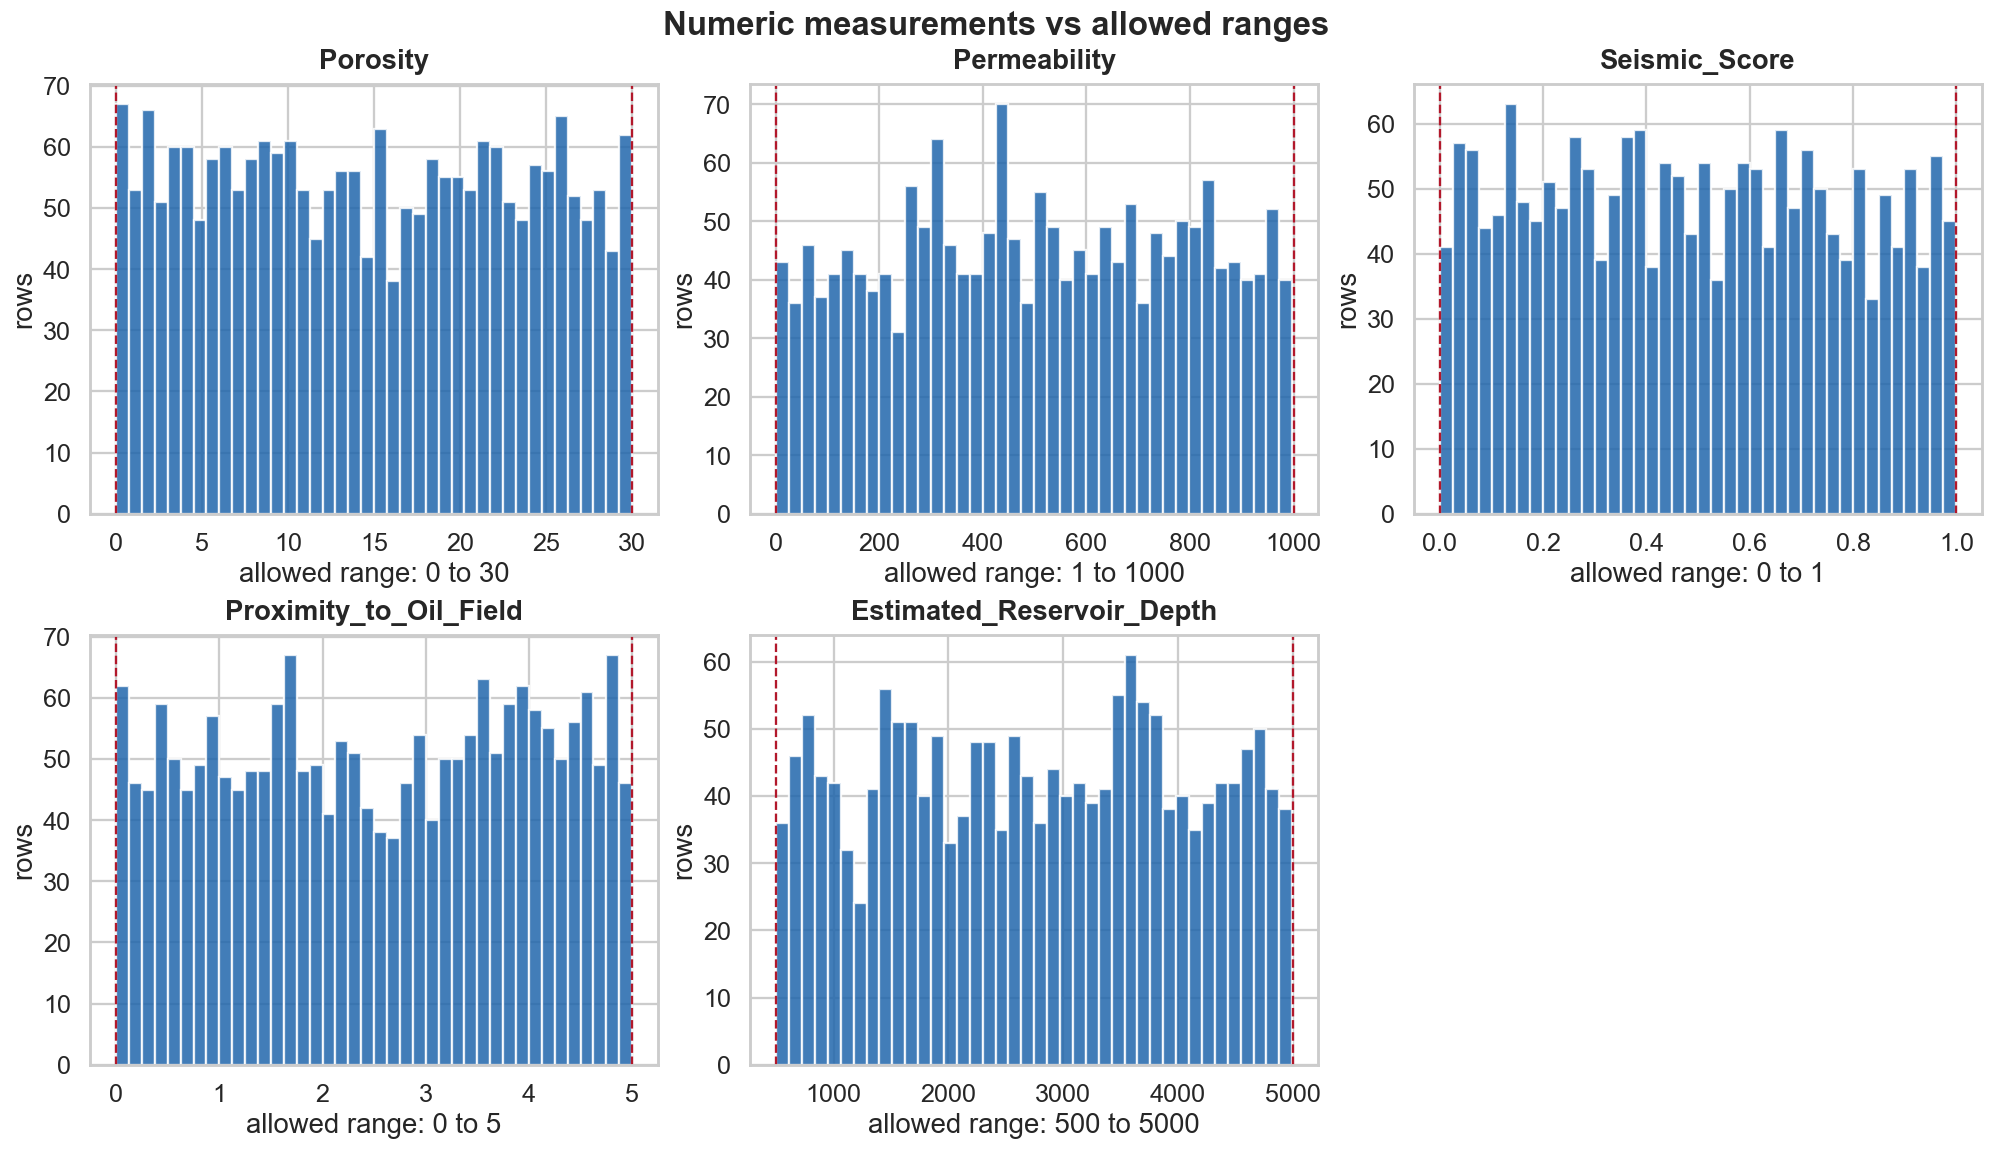

,feature,allowed_range,outside_range,missing_%
0,Porosity,0 to 30,0,26.8
1,Permeability,1 to 1000,0,39.5
2,Seismic_Score,0 to 1,0,35.0
3,Proximity_to_Oil_Field,0 to 5,0,31.4
4,Estimated_Reservoir_Depth,500 to 5000,0,42.3


In [ ]:
# Do the measurements sit inside their sensible physical ranges?
fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.ravel()

for i, col in enumerate(NUMERIC):
    series = train_raw[col].dropna()
    low, high = PHYSICAL_RANGES[col]

    axes[i].hist(series, bins=40, color=BLUE, alpha=0.85, edgecolor="white")
    axes[i].axvline(low, color=RED, ls="--", lw=1.5)
    axes[i].axvline(high, color=RED, ls="--", lw=1.5)

    axes[i].set_title(col, pad=10)
    axes[i].set_xlabel(f"allowed range: {low} to {high}")
    axes[i].set_ylabel("rows")

axes[-1].axis("off")
plt.suptitle("Numeric measurements vs allowed ranges", y=1.03, fontweight="bold")
plt.savefig("figures/03_distributions.png", bbox_inches="tight")
plt.show()

range_check = []
for col in NUMERIC:
    series = train_raw[col].dropna()
    low, high = PHYSICAL_RANGES[col]
    range_check.append({
        "feature": col,
        "allowed_range": f"{low} to {high}",
        "outside_range": int(((series < low) | (series > high)).sum()),
        "missing_%": round(train_raw[col].isna().mean() * 100, 1),
    })
display(pd.DataFrame(range_check))

**Figure 3.** Every numeric column is roughly flat and sits inside its expected range, with nothing
out of bounds. So, the anomalies which were stated in the brief for the competition are not simply numbers that are too big or too
small.

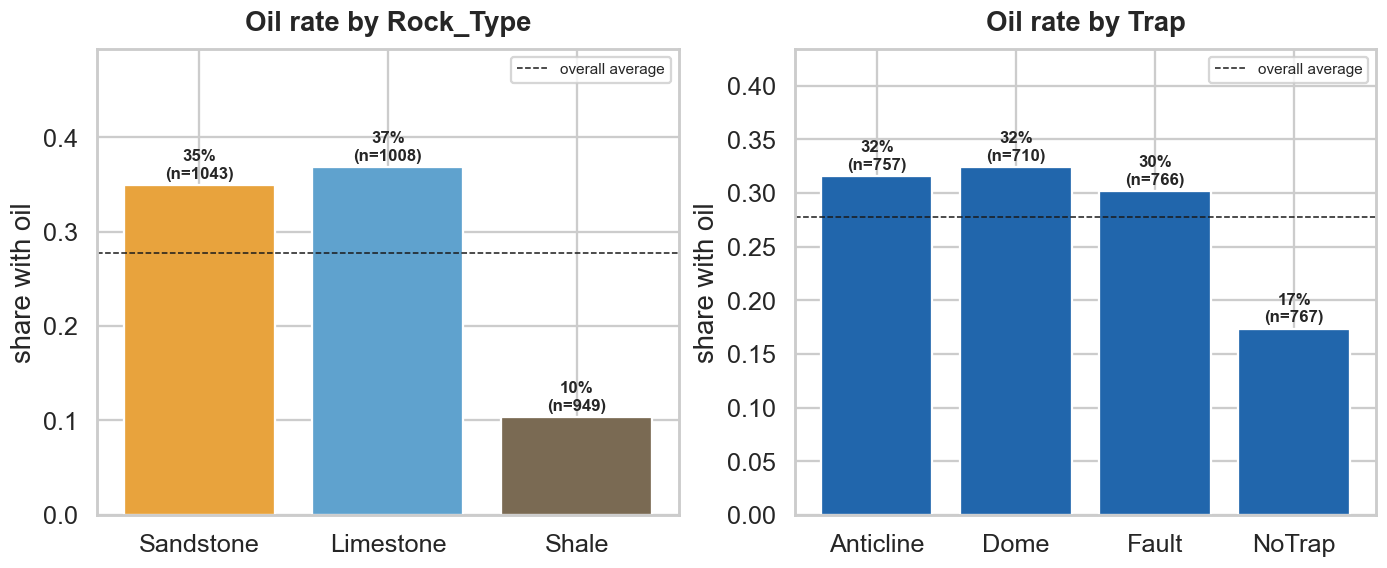

In [ ]:
# Oil rate by rock type and by trap type.
tmp = train_raw.copy()
tmp["Trap_disp"] = tmp["Trap_Type"].fillna("NoTrap")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

for axis, col, order in [(ax[0], "Rock_Type", ["Sandstone", "Limestone", "Shale"]),
                         (ax[1], "Trap_disp", ["Anticline", "Dome", "Fault", "NoTrap"])]:
    g = tmp.groupby(col)[TARGET].agg(["mean", "count"]).reindex(order)
    bars = axis.bar(g.index, g["mean"], color=[ROCK_COLOURS.get(x, BLUE) for x in g.index])
    axis.axhline(tmp[TARGET].mean(), ls="--", c="k", lw=1, label="overall average")
    axis.set_ylim(0, g["mean"].max() * 1.34)

    for bar, (m, n) in zip(bars, g.itertuples(index=False)):
        axis.text(bar.get_x() + bar.get_width() / 2, m + g["mean"].max() * 0.02,
                  f"{m:.0%}\n(n={n})", ha="center", fontweight="bold", fontsize=11)

    axis.set_title(f"Oil rate by {col.replace('_disp', '')}", pad=12)
    axis.set_ylabel("share with oil")
    axis.legend(loc="upper right", fontsize=10)

plt.savefig("figures/04_categorical_controls.png", bbox_inches="tight")
plt.show()

**Figure 4.** This is textbook geology. Shale drops to about 10 percent oil because it is a seal, not
a reservoir, while sandstone and limestone sit near 35 percent. And having no trap roughly halves the
oil rate compared with any of the three real traps. Two of the petroleum system gates, reservoir and
trap, are already visible.

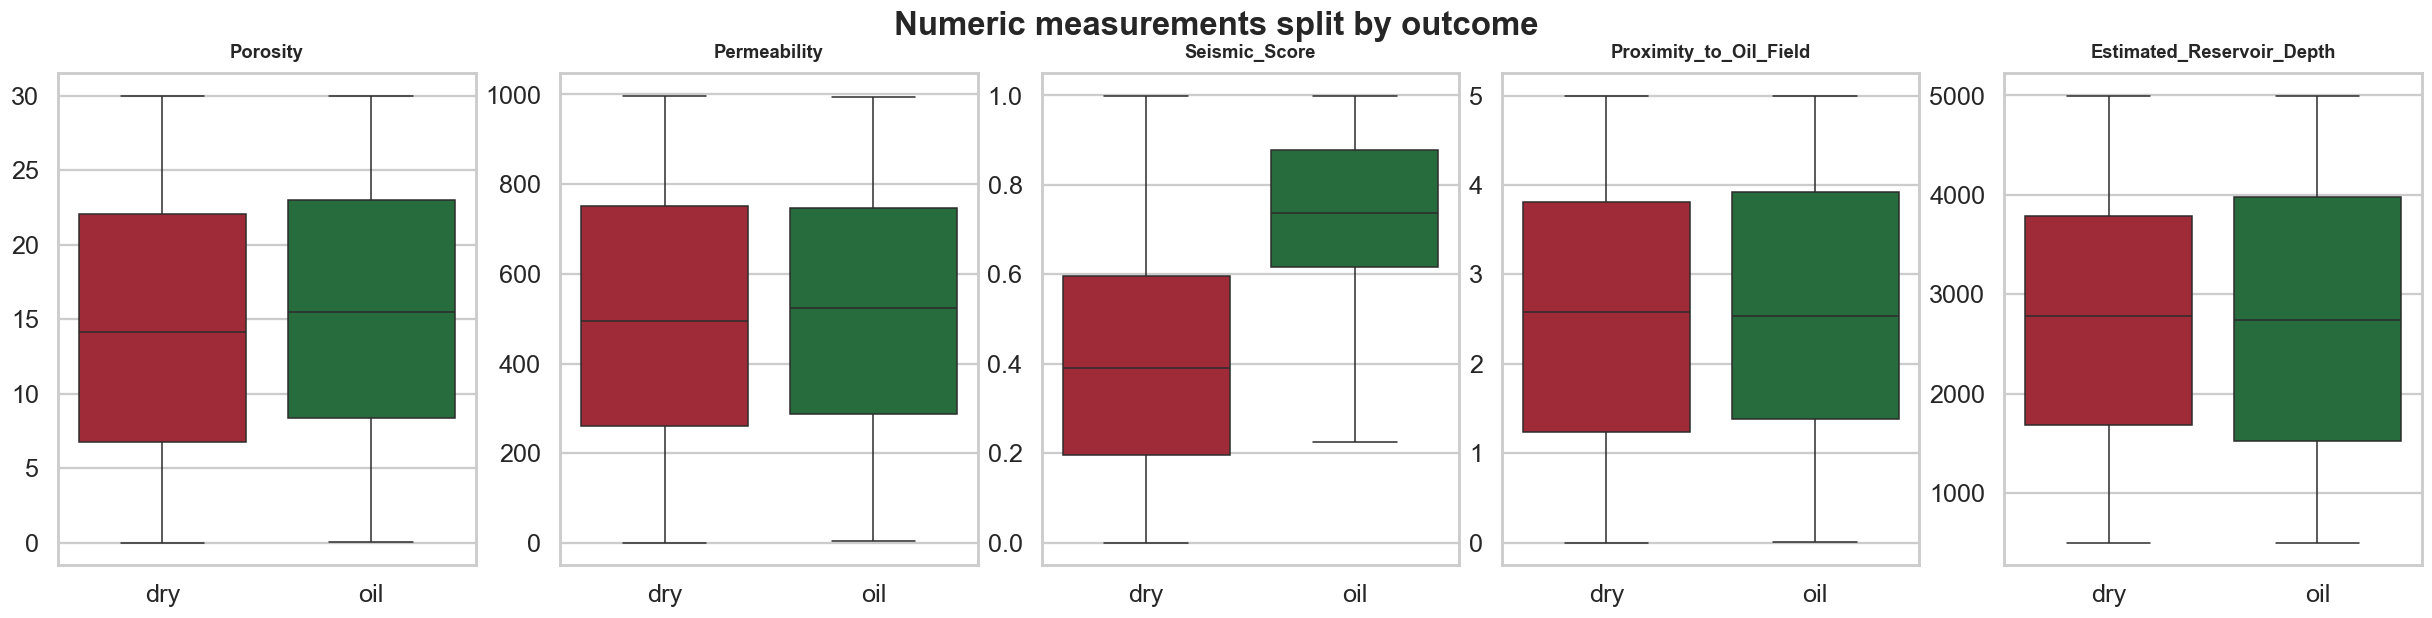

,feature,correlation_with_oil
0,Porosity,0.045
1,Permeability,0.018
2,Seismic_Score,0.419
3,Proximity_to_Oil_Field,0.014
4,Estimated_Reservoir_Depth,0.006


In [ ]:
# Which numeric measurements actually separate oil from dry?
from scipy.stats import pointbiserialr

fig, axes = plt.subplots(1, 5, figsize=(22, 5.2), constrained_layout=True)
corrs = {}

for axis, col in zip(axes, NUMERIC):
    d = train_raw[[col, TARGET]].dropna()
    r, _ = pointbiserialr(d[TARGET], d[col])
    corrs[col] = r
    sns.boxplot(data=train_raw, x=TARGET, y=col, ax=axis, palette=[RED, GREEN], showfliers=False)
    axis.set_title(col, fontsize=12, pad=10)
    axis.set_xlabel("")
    axis.set_ylabel("")
    axis.set_xticklabels(["dry", "oil"])

plt.suptitle("Numeric measurements split by outcome", y=1.05, fontweight="bold")
plt.savefig("figures/05_numeric_vs_target.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "feature": list(corrs.keys()),
    "correlation_with_oil": [round(v, 3) for v in corrs.values()],
}))

**Figure 5.** This figure shows us that only Seismic_Score clearly separates oil from dry (correlation about +0.42). Porosity,
permeability, proximity and depth have boxes that almost completely overlap, so on their own they are
closer to noise than signal in this dataset. That is a surprising but useful finding.

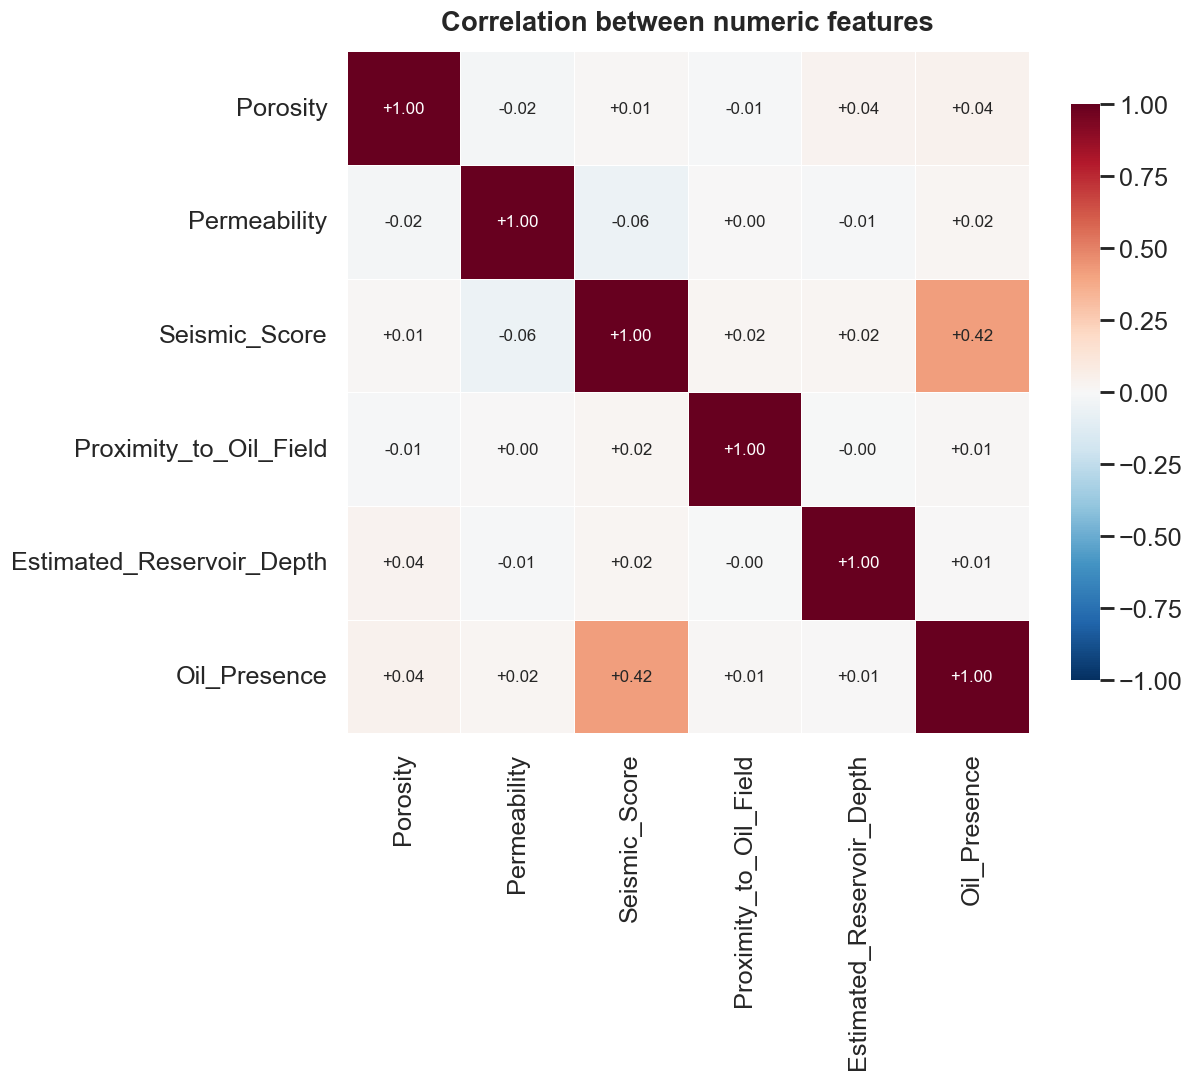

Porosity vs Permeability correlation: -0.018


In [ ]:
# The correlation grid, mostly to confirm one suspicious pair.
corr = train_raw[NUMERIC + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 11}, linewidths=0.5, ax=ax)
ax.set_title("Correlation between numeric features", pad=14)
plt.setp(ax.get_yticklabels(), rotation=0)
plt.savefig("figures/06_correlation.png", bbox_inches="tight")
plt.show()

print("Porosity vs Permeability correlation:", round(corr.loc["Porosity", "Permeability"], 3))

**Figure 6.** The target correlates almost only with Seismic_Score. The interesting part is that
porosity and permeability are basically approximately uncorrelated with each other (about -0.02), which is in diagreement with the expected porosity vs permeability behaviour. So, this is the first geological inconsistency spotted and investigated.

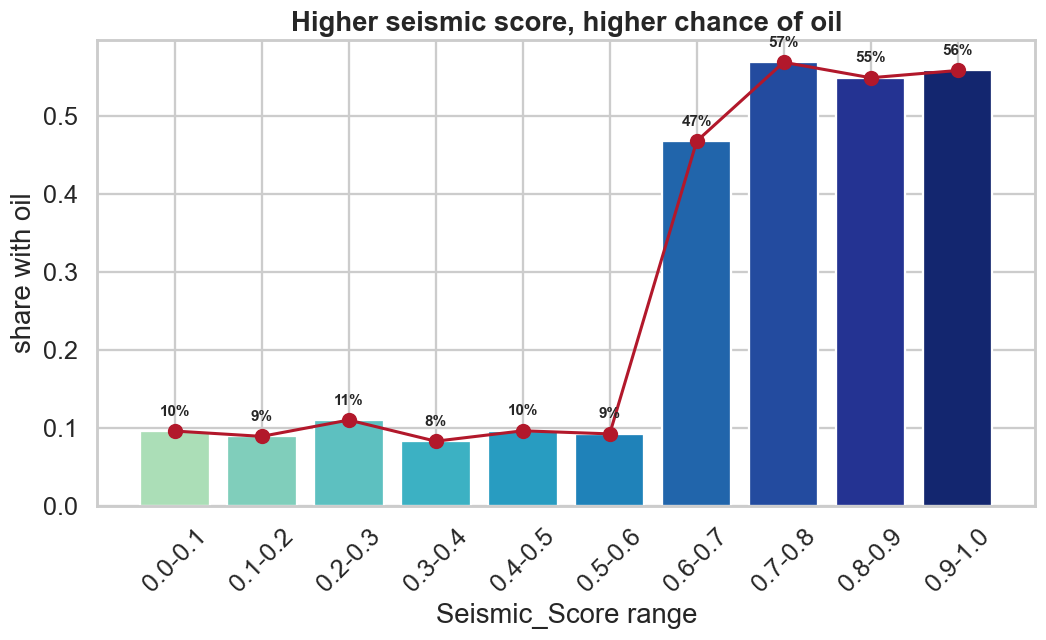

In [ ]:
# The star feature up close: does more seismic mean more oil?
tmp = train_raw.dropna(subset=["Seismic_Score"]).copy()
tmp["bin"] = pd.cut(tmp["Seismic_Score"], np.linspace(0, 1, 11))
g = tmp.groupby("bin", observed=True)[TARGET].mean()

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(g))
ax.bar(x, g.values, color=plt.cm.YlGnBu(np.linspace(0.3, 0.95, len(g))))
ax.plot(x, g.values, "o-", color=RED, lw=2)
ax.set_xticks(x)
ax.set_xticklabels([f"{iv.left:.1f}-{iv.right:.1f}" for iv in g.index], rotation=45)
ax.set_xlabel("Seismic_Score range")
ax.set_ylabel("share with oil")
ax.set_title("Higher seismic score, higher chance of oil")
for xi, m in zip(x, g.values):
    ax.text(xi, m + 0.02, f"{m:.0%}", ha="center", fontsize=10, fontweight="bold")

plt.savefig("figures/07_seismic_dhi.png", bbox_inches="tight")
plt.show()

**Figure 7.** Oil rate climbs smoothly from about 10 percent up to roughly 56 percent as the seismic
score rises. That clean, one directional climb is exactly how a good direct hydrocarbon indicator
behaves. It is our single strongest signal, and the reason the training rows that are missing a
seismic score are such a handicap.

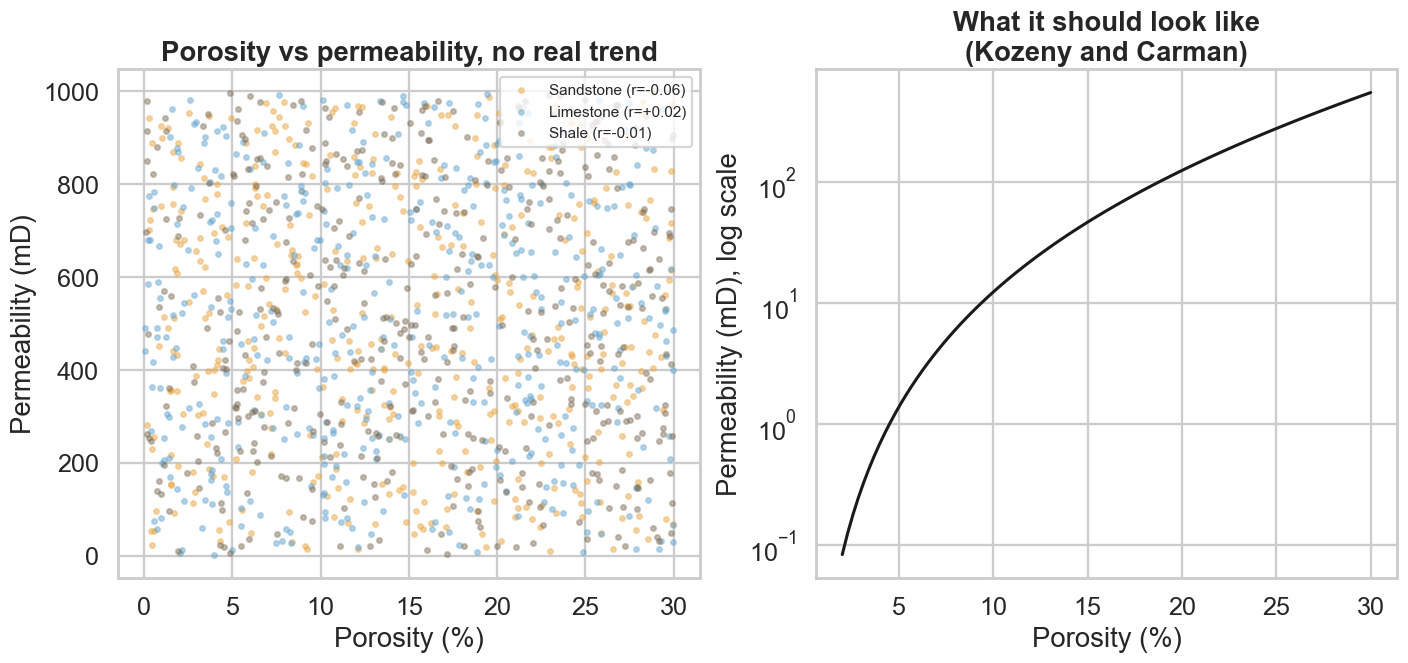

In [ ]:
# The contradiction: in real rock, more porosity means more permeability. Here it does not.
pp = train_raw.dropna(subset=["Porosity", "Permeability"]).copy()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

for rock in ["Sandstone", "Limestone", "Shale"]:
    s = pp[pp.Rock_Type == rock]
    r = s["Porosity"].corr(s["Permeability"])
    ax[0].scatter(s["Porosity"], s["Permeability"], s=10, alpha=0.4,
                  color=ROCK_COLOURS[rock], label=f"{rock} (r={r:+.2f})")
ax[0].set_xlabel("Porosity (%)")
ax[0].set_ylabel("Permeability (mD)")
ax[0].set_title("Porosity vs permeability, no real trend")
ax[0].legend(fontsize=10)

phi = np.linspace(2, 30, 100) / 100
ax[1].plot(phi * 100, 0.1 * (phi ** 3) / ((1 - phi) ** 2) * 1e5, color="k", lw=2)
ax[1].set_yscale("log")
ax[1].set_xlabel("Porosity (%)")
ax[1].set_ylabel("Permeability (mD), log scale")
ax[1].set_title("What it should look like\n(Kozeny and Carman)")

plt.savefig("figures/08_poroperm_anomaly.png", bbox_inches="tight")
plt.show()

**Figure 8.** In real rock, porosity and permeability go up together in a tight cloud as shown on the right panel. In the dataset, the
relationship is flat for every rock type.

Another geological inconsistency spotted was shale possessing reservoir grade permeability, with some values even exceeding 800mD. This is far from the expected permeability range for a seal rock. This was handled and extensively discussed in part 2.


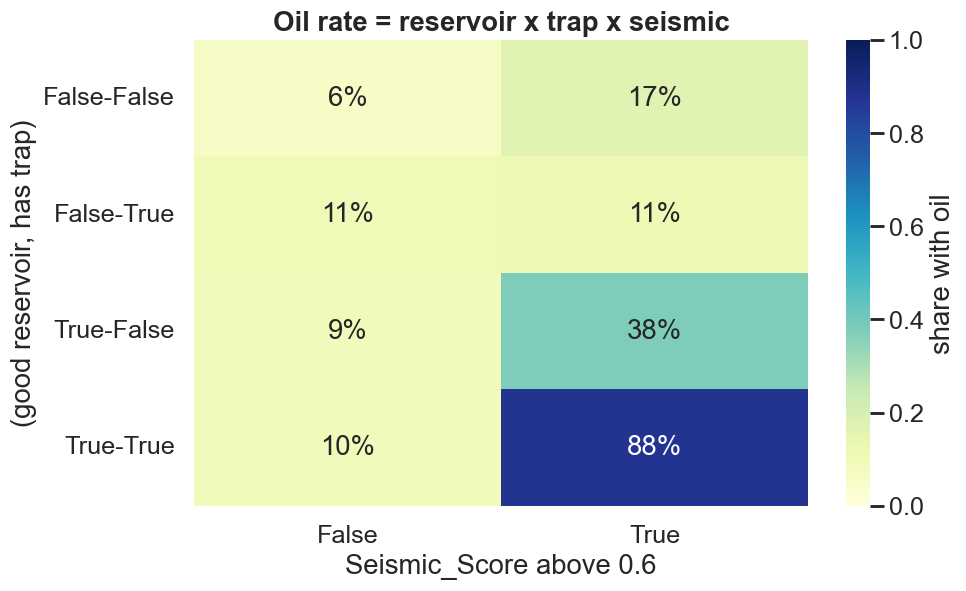

In [ ]:
# Proof that oil needs all three things at once.
tmp = train_raw.copy()
tmp["has_trap"] = tmp["Trap_Type"].fillna("NoTrap").ne("NoTrap")
tmp["good_reservoir"] = tmp["Rock_Type"].isin(["Sandstone", "Limestone"])
tmp["strong_seismic"] = tmp["Seismic_Score"] > 0.6

pivot = (tmp.dropna(subset=["Seismic_Score"])
            .groupby(["good_reservoir", "has_trap", "strong_seismic"])[TARGET]
            .mean()
            .unstack())

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1,
            cbar_kws={"label": "share with oil"}, ax=ax)
ax.set_title("Oil rate = reservoir x trap x seismic")
ax.set_xlabel("Seismic_Score above 0.6")
ax.set_ylabel("(good reservoir, has trap)")
plt.savefig("figures/09_and_gate.png", bbox_inches="tight")
plt.show()

**Figure 9.** This is the most important chart in the project. It shows that a good rock, a real trap, and a strong seismic score gives about 85 to 90 percent oil. Remove any of the three and it drops
back toward 10 percent. The features multiply; they do not add. This is exactly the petroleum system idea, and it is what both parts of the model end up learning.



## **IMPORTANT CONCLUSIONS FROM THE EDA**

* **Porosity versus permeability relationship is inconistent with the expected geological behaviour.**
* **Many shale permeability values exceeded the expected geological permeability range.**
* **Discovery is a combination:** The combination of a quality reservoir rock, a trap, and a strong seismic score creates the highest probability of discovering oil.
* **Seismic_Score is the most important feature.**
* **Shale is almost always a dry hole.**
* **Porosity, permeability, proximity and depth carry little signal on their own.**
* **The are many missing values in the training set but the test set is almost complete. So, careful imputation is requires to avoid distorting the data.**

## 3. PART 1: A STANDARD MACHINE LEARNING WORKFLOW

This is the pure data science half.  We:
1.  **Fix the trap labels:** Replace "None" and "NoTrap" with NoTrap
2.  **Fill the gaps with simple statistics:** Numerical values with missing values were filled with their median values. Note that for logistic regression and MLP algorithms, standardization was performed on the numerical features. This is because the features are of different magnitudes and these models are sensitive to numerical features with different scales.
3.  **Encode the categories:** Categorical features were imputed  using the most frequent observation (mode) by applying a column transformer containing the different preprocessing pipelines.
1.  **Add a few obvious features:**

* **has_trap:** This feature indicates whether a trap is present or not. One's implies presence of a trap while zeroes suggests otherwise.
* **is_shale:** This feature is an indicator that the rock type feature in a row is shale. Ones imply that the rock type is a shale while zeros suggest otherwise.
* **seismic_x_trap:** This feature multiplies the seismic score by the trap presence score.

$$
\text{Seismic_x_Trap} = \text{Seismic_Score} \times \text{Has_Trap}
$$

* **seismic_squared:** The features squares the seismic score.

$$
\text{Seismic_Squared} = (\text{Seismic_Score})^2
$$

5. **Integrate the different algorithms (except the underperforming Logistic Regression and MLP) through the same fair
five fold cross validation into an Ensemble model using the voting classifier. The voting ensemble averages the probabilities from the different model to conclude on the final probability and class.**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix, roc_curve)
from lightgbm import LGBMClassifier

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def reconcile_trap(df):
    # "None" in train and a blank in test mean the same thing, so we line them up.
    d = df.copy()
    d["Trap_Type"] = d["Trap_Type"].replace("", np.nan).fillna("NoTrap").replace("None", "NoTrap")
    return d


def part1_features(df):
    d = reconcile_trap(df)
    d["has_trap"] = (d["Trap_Type"] != "NoTrap").astype(int)
    d["is_shale"] = (d["Rock_Type"] == "Shale").astype(int)
    d["seismic_x_trap"] = d["Seismic_Score"] * d["has_trap"]
    d["seismic_squared"] = d["Seismic_Score"] ** 2
    return d


P1_NUM = NUMERIC + ["has_trap", "is_shale", "seismic_x_trap", "seismic_squared"]
P1_CAT = CATEGORICAL

X1_train = part1_features(train_raw)
X1_test = part1_features(test_raw)

In [ ]:
# Preprocessing: fill gaps, scale where it helps, one hot encode the categories.
def make_preprocessor(scale=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))

    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), make_column_selector(dtype_include=np.number)),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), make_column_selector(dtype_include=object)),
    ])


def build_models():
    models = {
        "Logistic Regression": (make_preprocessor(scale=True),
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        "Random Forest": (make_preprocessor(),
            RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)),
        "Extra Trees": (make_preprocessor(),
            ExtraTreesClassifier(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1)),
        "HistGradientBoosting": (make_preprocessor(),
            HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_depth=4,
                                           l2_regularization=2.0, min_samples_leaf=40,
                                           random_state=RANDOM_STATE)),
        "LightGBM": (make_preprocessor(),
            LGBMClassifier(n_estimators=700, learning_rate=0.02, num_leaves=31,
                           reg_lambda=2.0, random_state=RANDOM_STATE, verbose=-1)),
        "Neural Net (MLP)": (make_preprocessor(scale=True),
            MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600, early_stopping=True,
                          random_state=RANDOM_STATE)),
    }
    if HAS_XGB:
        from xgboost import XGBClassifier
        models["XGBoost"] = (make_preprocessor(),
            XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=5, subsample=0.8,
                          colsample_bytree=0.8, reg_lambda=2.0, eval_metric="logloss",
                          random_state=RANDOM_STATE, n_jobs=-1))
    return models

In [ ]:
# Compare every model with the same five fold cross validation.
def score_models(models, X, target):
    rows = {}
    for name, (pre, clf) in models.items():
        pipe = Pipeline([("pre", pre), ("clf", clf)])
        oof = cross_val_predict(pipe, X, target, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
        pred = (oof > 0.5).astype(int)
        rows[name] = {
            "Accuracy": accuracy_score(target, pred),
            "Precision": precision_score(target, pred),
            "Recall": recall_score(target, pred),
            "F1": f1_score(target, pred),
            "ROC-AUC": roc_auc_score(target, oof),
            "PR-AUC": average_precision_score(target, oof),
            "Acc (rows with seismic)": accuracy_score(target[has_seismic], pred[has_seismic]),
        }
    table = pd.DataFrame(rows).T.sort_values("Accuracy", ascending=False)
    return table

p1_scores = score_models(build_models(), X1_train[P1_NUM + P1_CAT], y)
print("Part 1, five fold cross validation (PR-AUC random baseline is about 0.28):")
p1_scores.round(4)

/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Part 1, five fold cross validation (PR-AUC random baseline is about 0.28):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Acc (rows with seismic)
HistGradientBoosting,0.8130,0.7403,0.5030,0.5990,0.8089,0.6796,0.8779
XGBoost,0.8100,0.7240,0.5102,0.5986,0.8132,0.6807,0.8815
Random Forest,0.8097,0.6985,0.5534,0.6175,0.8033,0.6686,0.8872
Logistic Regression,0.8067,0.7976,0.4070,0.5390,0.7917,0.6546,0.8651
Extra Trees,0.8043,0.6847,0.5474,0.6084,0.7877,0.6448,0.8759
LightGBM,0.8043,0.6952,0.5258,0.5988,0.8084,0.6762,0.8826
Neural Net (MLP),0.8020,0.7786,0.4010,0.5293,0.7963,0.6558,0.8564


**Reading the table.** The tree models cluster around 0.80 accuracy on all rows and about 0.88 on the
rows that have a seismic score, with PR-AUC near 0.68, well above the 0.28 random baseline. The neural
network sits at the bottom, which is expected on a small table like this, so we lead with the trees.

In [ ]:
# The tree models scored close together, so we average the best of them in a soft voting ensemble.
def build_ensemble():
    members = []
    for name, (pre, clf) in build_models().items():
        if name in ("Logistic Regression", "Neural Net (MLP)"):
            continue
        members.append((name, Pipeline([("pre", pre), ("clf", clf)])))
    return VotingClassifier(members, voting="soft", n_jobs=-1)


ensemble_p1 = build_ensemble()
oof_p1 = cross_val_predict(ensemble_p1, X1_train[P1_NUM + P1_CAT], y, cv=CV,
                           method="predict_proba", n_jobs=-1)[:, 1]
pred_p1 = (oof_p1 > 0.5).astype(int)

print("Part 1 ensemble, out of fold:")
print("  accuracy all / seismic rows:",
      round(accuracy_score(y, pred_p1), 4), "/",
      round(accuracy_score(y[has_seismic], pred_p1[has_seismic]), 4))
print("  precision / recall / F1:",
      round(precision_score(y, pred_p1), 3), "/",
      round(recall_score(y, pred_p1), 3), "/",
      round(f1_score(y, pred_p1), 3))
print("  ROC-AUC / PR-AUC:",
      round(roc_auc_score(y, oof_p1), 4), "/",
      round(average_precision_score(y, oof_p1), 4))

/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Part 1 ensemble, out of fold:
  accuracy all / seismic rows: 0.8117 / 0.8846
  precision / recall / F1: 0.726 / 0.517 / 0.604
  ROC-AUC / PR-AUC: 0.8131 / 0.6826


/Users/macbook/Desktop/SPE DSEATS 2026 Datathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


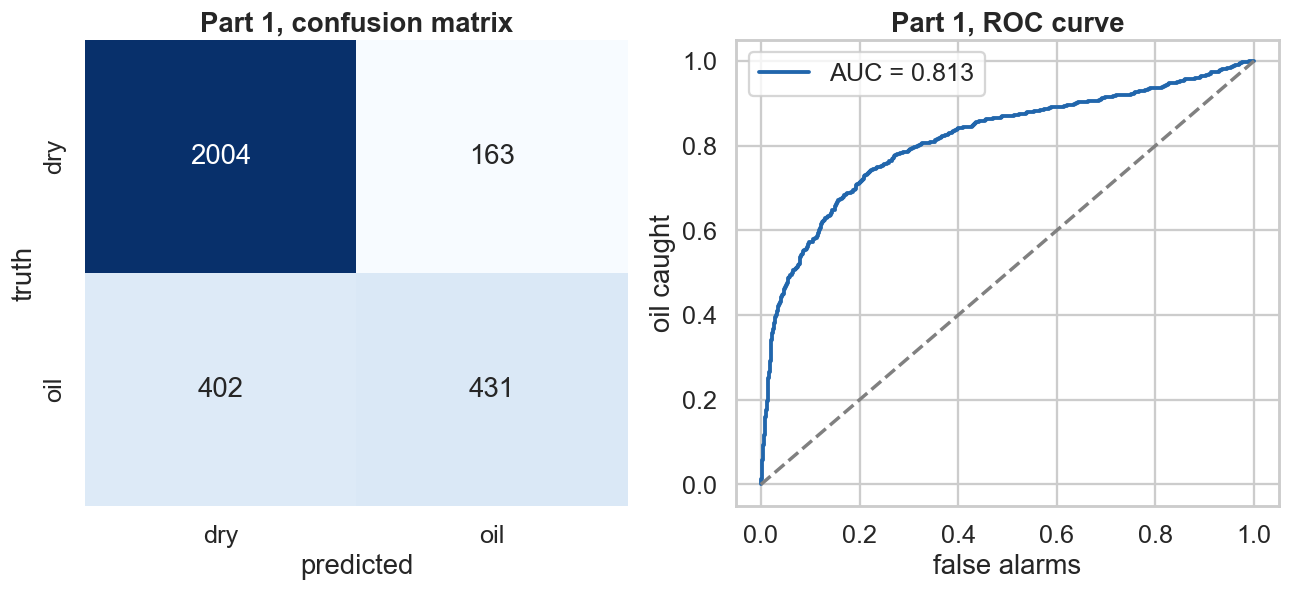

In [ ]:
# Two standard diagnostic plots.
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

cm = confusion_matrix(y, pred_p1)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["dry", "oil"], yticklabels=["dry", "oil"])
ax[0].set_title("Part 1, confusion matrix")
ax[0].set_xlabel("predicted")
ax[0].set_ylabel("truth")

fpr, tpr, _ = roc_curve(y, oof_p1)
ax[1].plot(fpr, tpr, color=BLUE, lw=2.5, label=f"AUC = {roc_auc_score(y, oof_p1):.3f}")
ax[1].plot([0, 1], [0, 1], "--", c="grey")
ax[1].set_title("Part 1, ROC curve")
ax[1].set_xlabel("false alarms")
ax[1].set_ylabel("oil caught")
ax[1].legend()

plt.savefig("figures/10_part1_diagnostics.png", bbox_inches="tight")
plt.show()

**Figure 10.** The confusion matrix shows where we were right and wrong, and the ROC curve shows how
well the model ranks oil locations above dry ones. The area under that curve is about 0.81.

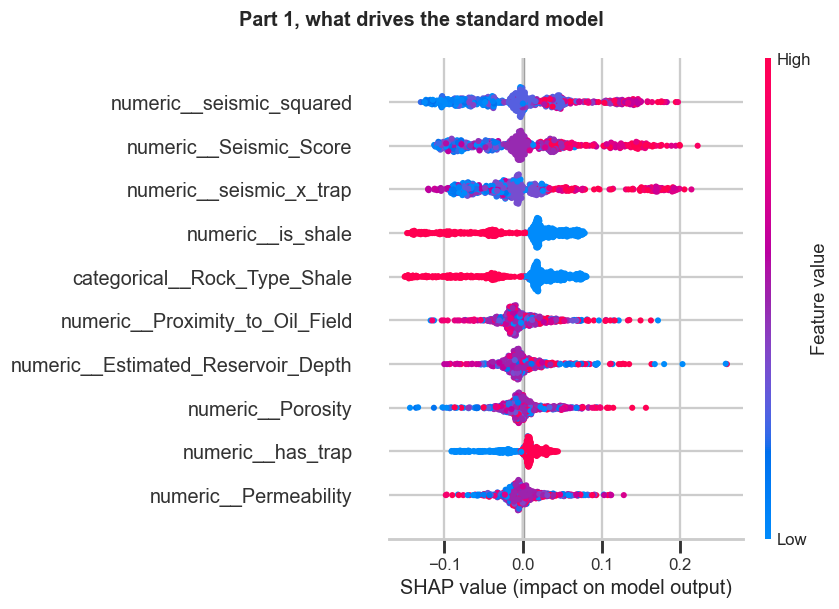

In [ ]:
# Which features does the Part 1 model lean on? (SHAP)
import shap

def shap_plot(fitted_member, X, filename, title):
    pre = fitted_member.named_steps["pre"]
    clf = fitted_member.named_steps["clf"]
    transformed = pre.transform(X)
    names = pre.get_feature_names_out()

    sample = shap.utils.sample(transformed, 700, random_state=RANDOM_STATE)
    values = shap.TreeExplainer(clf).shap_values(sample)
    if isinstance(values, list):
        values = values[1]
    elif getattr(values, "ndim", 2) == 3:
        values = values[..., 1]

    plt.figure()
    shap.summary_plot(values, sample, feature_names=names, max_display=10, show=False)
    plt.gcf().suptitle(title, fontsize=13, fontweight="bold", y=1.02)
    plt.savefig(filename, bbox_inches="tight")
    plt.show()


rf_p1 = Pipeline([("pre", make_preprocessor()),
                  ("clf", RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1))])
rf_p1.fit(X1_train[P1_NUM + P1_CAT], y)
shap_plot(rf_p1, X1_train[P1_NUM + P1_CAT], "figures/11_shap_part1.png",
          "Part 1, what drives the standard model")

**Figure 11.** Even before any geology features, the standard model leans on Seismic_Score, trap
presence and rock type, which are the petroleum system elements. So the signal it finds is
geologically sensible, not a coincidence.

In [ ]:
# Fit on all the training data and predict the test set, saving both class probabilities.
TEAM_NAME = "GeoSpark"

final_p1 = build_ensemble()
final_p1.fit(X1_train[P1_NUM + P1_CAT], y)

proba_test_p1 = final_p1.predict_proba(X1_test[P1_NUM + P1_CAT])[:, 1]
pred_test_p1 = (proba_test_p1 > 0.5).astype(int)

out1 = test_raw.copy()
out1["Probability_NoOil"] = (1 - proba_test_p1).round(4)
out1["Probability_Oil"] = proba_test_p1.round(4)
out1["Oil_Presence"] = pred_test_p1
out1.to_csv(f"{TEAM_NAME}_Prediction_Part1.csv", index=False)

print(f"Saved {TEAM_NAME}_Prediction_Part1.csv")
print("Predicted oil on test:", f"{pred_test_p1.mean():.1%}")

Saved GeoSpark_Prediction_Part1.csv
Predicted oil on test: 21.9%


# **4. PART 2: A PHYSICS-INFORMED LIGHT GRADIENT BOOSTING ALGORITHM**


Part 2 integrates domain knowledge with data science expertise to ensure that the model is consistent with petroleum physics.


## **Feature Engineering:**
**1. Log_Permeability:** Since reservoir permeability had a wide range of values, a log transformation was applied. This compresses the values, helps the model learn better, and prevents undefined values.



$$
\text{Log_Permeability} = \ln(1 + \text{Permeability})
$$


**2. Compaction Resistance Index (CRI):** Since reservoir porosity could decrease with depth due to compaction and cementation effects, the CRI feature was created to account for the variation of porosity with depth in real-world scenarios.



$$
CRI = \frac{\text{Porosity (fraction)}}{\text{Estimated Reservoir Depth}}
$$



**3. Trap Type Missing Indicator:** Since the data brief sent by the organizers said ‘no significant trap structure’, a trap missing indicator was created to help the model distinguish between known trap configurations and missing/inconclusive ones (which could occur during early exploration)


**4. Trap Type Weight:** Based on domain knowledge, anticlines and domes generally tend to be better hydrocarbon prospects. First, missing trap types were replaced with ‘Unknown’. Then, trap types were ranked using the oil occurrence rate on the training set to avoid subjective bias and data leakage. Then, the ranking was normalized so that the weights lie between zero and one. Finally, missing values were replaced with the global mean weight.


**5. Rock Type Weight:** Reservoir rocks have different storage and flow capacities. First, a threshold value was set at 100mD, giving room for the rare occurrence that a shale value would exceed 10mD (This helps to account for unique scenarios). Then, shale values exceeding 100mD were renamed as misclassified lithology.


Furthermore, rock types were weighted using the oil occurrence rate on the training data to avoid subjective bias and data leakage.


**6. Trap Confidence Index:** An important criterion for hydrocarbon presence is the existence of a trap. Therefore, an integrated feature (Trap Confidence Index) that captures the interaction between the seismic score and trap type weight was created.


$$
\text{Trap Confidence Index} = (\text{Seismic Score}) \cdot (W_{\text{Trap Type}})
$$


**7. Charge Potential:** The probability of hydrocarbon charge decreases as the distance increases because they could share the same source rocks and migration pathways. This tranformed feature attaches higher weights to closer distances and vice versa. This tranformation is essential for easy interpretation of the feature and directional consistency among the weights that make up the chance of success feature. Consequently, leading to a more reliable interpretation of the C.O.S feature. The inverse distance plus one was used to smooth the decay and avoid division by zero errors.

$$
\text{Charge Potential} = \frac{1}{\text{Proximity to Oil Field}  + 1}
$$



**8. Chance of Success:** Based on Domain knowledge and the EDA results, hydrocarbon presence requires a sufficient charge and a good reservoir quality. So, a chance of success feature was engineered to capture the interaction between the three essential elements.


$$
\text{Chance of Success} = W_{\text{Rock Type}} \cdot W_{\text{Trap Type}} \cdot C_{\text{Charge Potential}}
$$


Finally, porosity (fraction), charge potential, rock, and trap type weights were dropped to avoid feature redundancy and reduce the multicollinearity of the features.


## **Train Validation Strategy:**
The train set was divided into a train set and a validation set using a ratio of 80 to 20. Due to the class imbalance, the train validation split was stratified with the oil presence column. This stratification preserves the oil vs non-ratio in both sets.


## **Hyperparameter Tuning and Cross Validation Strategy:**
Bayesian Optimisation was used for hyperparameter tuning for efficient sample space exploration.


Compared to grid search or random sampling, Bayesian Optimisation builds a probabilistic surrogate model of the objective function (in this case: ROC-AUC). It uses this surrogate to predict the areas that improve model predictions and focuses on them.


Stratified five K-fold cross-validation was also implemented during the training to ensure that the fold approximately reflects the oil vs non-oil ratio, which makes the model more reliable.


## **Model Selection:**


Apart from returning the best results, LightGBM was selected for part 2 because of its ability to handle missing values natively. This is crucial to part 2 workflow, where imputations were broadly avoided to preserve the inherent nature of the data.


Another reason for its selection was its fast training. This is crucial for Bayesian Optimisation hyperparameter tuning, where many trials were performed..


Lastly, LightGBM handles numerical and categorical features easily. This is important since the day contains important categorical and numerical features.


## **SHAP Feature Importance Interpretation and Subsurface Physics Consistency:**


**Some key points:**


**1. Seismic Score:** This was the most important predictor feature for the model, as it ranked first. As shown in the SHAP plot, high seismic scores (red) fall on the positive side, while low seismic scores (blue) fall on the negative. The generally smooth monotonic transition from blue to red shows that higher seismic scores increase the chance of discovering oil and vice versa. This is consistent with petroleum physics and gives more credence to the model.


**2. Trap Type Missing:** This particular result is especially intriguing. Missing trap scores consistently returned non-zero SHAP contributions. This shows that missing trap values are important and that the model was able to differentiate whether a trap was known or unknown.
Consequently, without this feature, this information could have been lost. This gives credence to the model approach to control imputations to the barest minimum. Furthermore, the fact that it ranks high signifies that engineering the feature was beneficial.


**3. Compaction Resistance Index:** Although this feature ranked last, it considers geological zones where compaction and cementation effects are significant.


In conclusion, the model is broadly consistent with petroleum physics as shown in its generally smooth monotonic behaviour as well as the high ranking of geophysical features.


Additionally, the significance of the engineered features indicates that integrating domain knowledge not only improves model predictions but also explainability.




In [ ]:
# Part 2 physics features. We learn the category weights only from a reference training set,
# which we pass in, so that the weights never peek at the rows we are scoring (no leakage).
def prepare_categories(d):
    d = d.copy()
    d["Trap_Type"] = d["Trap_Type"].fillna("Unknown")
    # high permeability shale is not really shale, so we relabel it as Misclassified_Lithology
    is_misclassified = (d["Rock_Type"] == "Shale") & (d["Permeability"] > 100)
    d.loc[is_misclassified, "Rock_Type"] = "Misclassified_Lithology"
    return d


def category_weight(reference, column):
    # average oil rate per category, turned into the ranking used by the final Part 2 notebook
    oil_rate = reference.groupby(column)["Oil_Presence"].mean().sort_values(ascending=False)
    rank = oil_rate.rank(ascending=False, method="dense")
    score = rank / rank.max()
    return score, score.mean()


def physics_features(df, reference):
    original = df.copy()
    d = prepare_categories(df)
    ref = prepare_categories(reference)

    d["Log_Permeability"] = np.log1p(original["Permeability"])
    d["Compaction_Resistance_Index"] = (original["Porosity"] / 100) / original["Estimated_Reservoir_Depth"]
    d["Trap_Type_missing"] = original["Trap_Type"].isnull().astype(int)

    trap_weight, trap_default = category_weight(ref, "Trap_Type")
    rock_weight, rock_default = category_weight(ref, "Rock_Type")

    trap_w = d["Trap_Type"].map(trap_weight).fillna(trap_default)
    rock_w = d["Rock_Type"].map(rock_weight).fillna(rock_default)

    d["Trap_Confidence_Index"] = d["Seismic_Score"] * trap_w

    charge = 1 / (original["Proximity_to_Oil_Field"] + 1)
    d["Chance_of_Success"] = rock_w * trap_w * charge

    keep = ["Rock_Type", "Porosity", "Seismic_Score", "Proximity_to_Oil_Field",
            "Estimated_Reservoir_Depth", "Log_Permeability", "Compaction_Resistance_Index",
            "Trap_Type_missing", "Trap_Confidence_Index", "Chance_of_Success"]
    return d[keep]


# For the final model we learn the weights on the full training set.
X2_train = physics_features(train_raw, train_raw)
X2_test = physics_features(test_raw, train_raw)

X2_train["Rock_Type"] = X2_train["Rock_Type"].astype("category")
X2_test["Rock_Type"] = X2_test["Rock_Type"].astype("category")

print("Part 2 features:", list(X2_train.columns))
X2_train.head()

Part 2 features: ['Rock_Type', 'Porosity', 'Seismic_Score', 'Proximity_to_Oil_Field', 'Estimated_Reservoir_Depth', 'Log_Permeability', 'Compaction_Resistance_Index', 'Trap_Type_missing', 'Trap_Confidence_Index', 'Chance_of_Success']


,Rock_Type,Porosity,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Log_Permeability,Compaction_Resistance_Index,Trap_Type_missing,Trap_Confidence_Index,Chance_of_Success
0,Limestone,17.667992,0.705933,2.431355,2228.0,6.727764,0.000079,1,0.705933,0.072858
1,Limestone,27.665758,0.545806,2.606158,1610.0,6.361575,0.000172,1,0.545806,0.069326
2,Sandstone,28.855946,0.167530,1.143136,2344.0,6.005837,0.000123,1,0.167530,0.233303
3,Sandstone,0.410957,0.026852,2.673532,NaN,6.789913,NaN,0,0.006713,0.034027
4,Misclassified_Lithology,16.490538,NaN,2.064440,NaN,6.333792,NaN,1,NaN,0.244743


In [ ]:
# How many shale rows did we relabel, and how do the rock groups compare on oil rate?
relabelled = ((train_raw["Rock_Type"] == "Shale") & (train_raw["Permeability"] > 100)).sum()
print("Shale rows relabelled as Misclassified_Lithology:", int(relabelled))

groups = X2_train.copy()
groups["oil"] = y
print("\nOil rate by rock group after relabelling:")
print(groups.groupby("Rock_Type")["oil"].agg(["count", "mean"]).round(3))

Shale rows relabelled as Misclassified_Lithology: 526

Oil rate by rock group after relabelling:
                         count   mean
Rock_Type                            
Limestone                 1008  0.368
Misclassified_Lithology    526  0.122
Sandstone                 1043  0.349
Shale                      423  0.080


The relabelled misclassified lithology doesn't return the same reservoir quality values as the sandstone and limestone rocktypes. This justifes why it was placed in its own category.

In [ ]:
# Part 2 LightGBM, with settings selected through an Optuna search.
from sklearn.model_selection import train_test_split

lgbm = LGBMClassifier(
    n_estimators=161,
    learning_rate=0.020922479707239747,
    max_depth=26,
    num_leaves=12,
    min_child_samples=13,
    random_state=RANDOM_STATE,
    verbose=-1,
)


def full_report(y_true, proba, threshold=0.5):
    pred = (proba > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall (Sensitivity)": recall_score(y_true, pred),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(y_true, pred),
        "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }


# A single 80/20 split, so we can show train and validation numbers clearly.
Xtr, Xval, ytr, yval = train_test_split(X2_train, y, test_size=0.2,
                                        random_state=RANDOM_STATE, stratify=y)
lgbm.fit(Xtr, ytr, categorical_feature=["Rock_Type"])

report = pd.DataFrame({
    "TRAIN (all rows)": full_report(ytr, lgbm.predict_proba(Xtr)[:, 1]),
    "VALIDATION (all rows)": full_report(yval, lgbm.predict_proba(Xval)[:, 1]),
})
print("Part 2 LightGBM, single 80/20 split, threshold 0.5:")
report.round(4)

Part 2 LightGBM, single 80/20 split, threshold 0.5:


,TRAIN (all rows),VALIDATION (all rows)
Accuracy,0.8517,0.8450
Precision,0.8555,0.8558
Recall (Sensitivity),0.5601,0.5329
Specificity,0.9637,0.9654
F1 Score,0.6770,0.6568
TP,373.0000,89.0000
TN,1671.0000,418.0000
FP,63.0000,15.0000
FN,293.0000,78.0000
ROC-AUC,0.9064,0.8396


**Reading the table.** Validation accuracy is about 0.84, with recall near 0.53 (it catches about
half the oil at the default threshold). In real world scenarios, tradeoffs on the threshold might have to be made depending on the risk tolerance of the investors. As expected, the model returned better results on the traindata, since it was fitted on it.

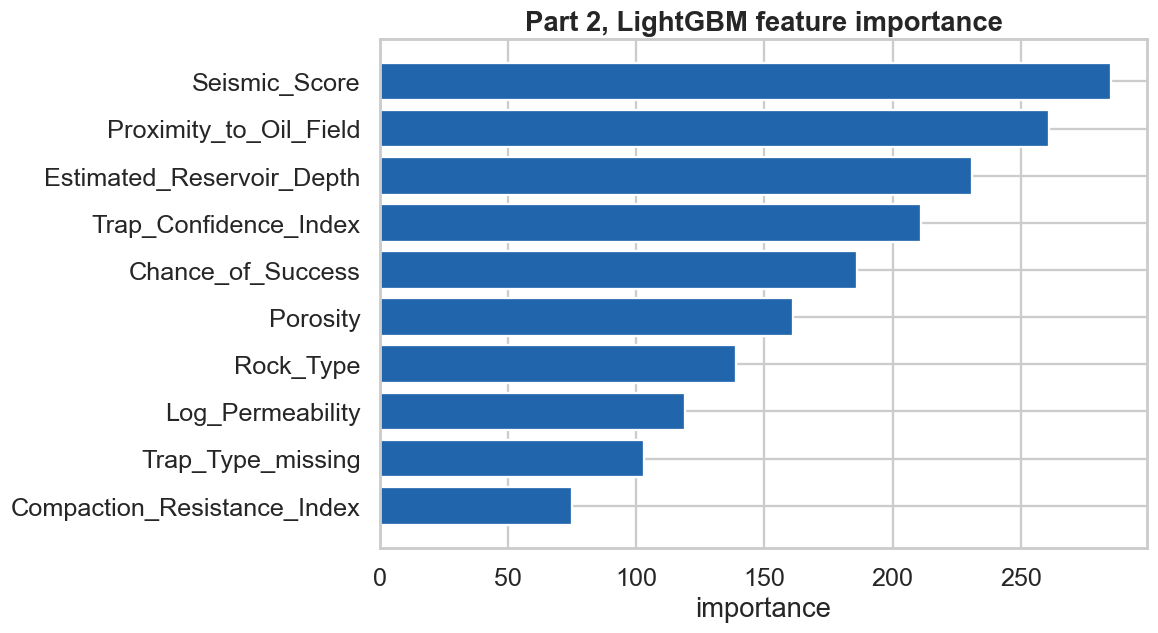

In [ ]:
# Feature importance and SHAP for the Part 2 model, fitted on all the training data.
lgbm.fit(X2_train, y, categorical_feature=["Rock_Type"])

importance = pd.DataFrame({
    "Feature": X2_train.columns,
    "Importance": lgbm.feature_importances_,
}).sort_values("Importance", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance["Feature"], importance["Importance"], color=BLUE)
ax.set_xlabel("importance")
ax.set_title("Part 2, LightGBM feature importance")
plt.savefig("figures/12_part2_importance.png", bbox_inches="tight")
plt.show()

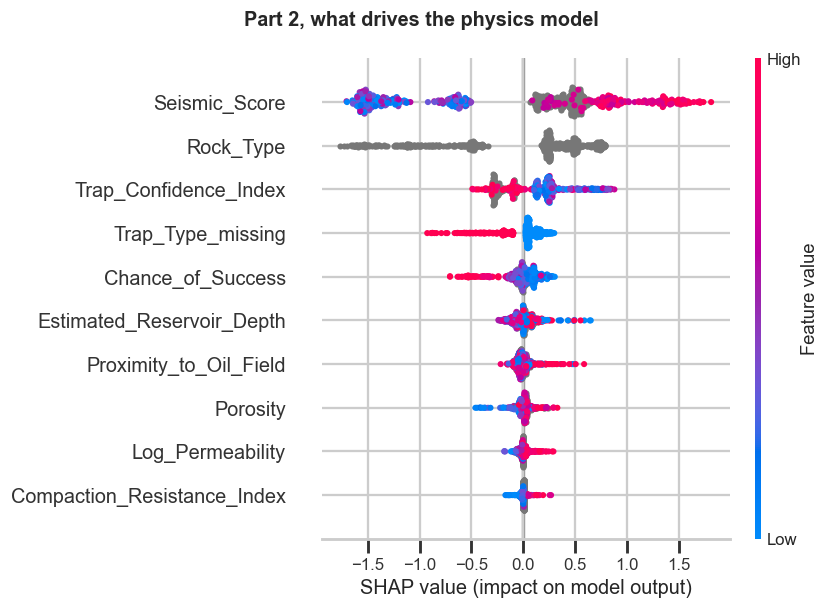

In [ ]:
# SHAP beeswarm for the Part 2 model.
sample = shap.utils.sample(X2_train, 700, random_state=RANDOM_STATE)
values = shap.TreeExplainer(lgbm).shap_values(sample)
if isinstance(values, list):
    values = values[1]
elif getattr(values, "ndim", 2) == 3:
    values = values[..., 1]

plt.figure()
shap.summary_plot(values, sample, max_display=10, show=False)
plt.gcf().suptitle("Part 2, what drives the physics model", fontsize=13, fontweight="bold", y=1.02)
plt.savefig("figures/13_shap_part2.png", bbox_inches="tight")
plt.show()

Both the feature importance and the SHAP plot concur that Seismic_Score, Trap Confidence Index and the Chance of Success score are the strong drivers, with rock type following closely. Thus emphasizing the place of physics informed models in the AI/ML applications in surbsurface disciplines.

In [ ]:
# Predict the test set with the Part 2 model, saving both class probabilities.
proba_test_p2 = lgbm.predict_proba(X2_test)[:, 1]
pred_test_p2 = (proba_test_p2 > 0.5).astype(int)

out2 = test_raw.copy()
out2["Probability_NoOil"] = (1 - proba_test_p2).round(4)
out2["Probability_Oil"] = proba_test_p2.round(4)
out2["Oil_Presence"] = pred_test_p2
out2.to_csv(f"{TEAM_NAME}_Prediction_Part2.csv", index=False)

print(f"Saved {TEAM_NAME}_Prediction_Part2.csv")
print("Predicted oil on test:", f"{pred_test_p2.mean():.1%}")

Saved GeoSpark_Prediction_Part2.csv
Predicted oil on test: 22.2%


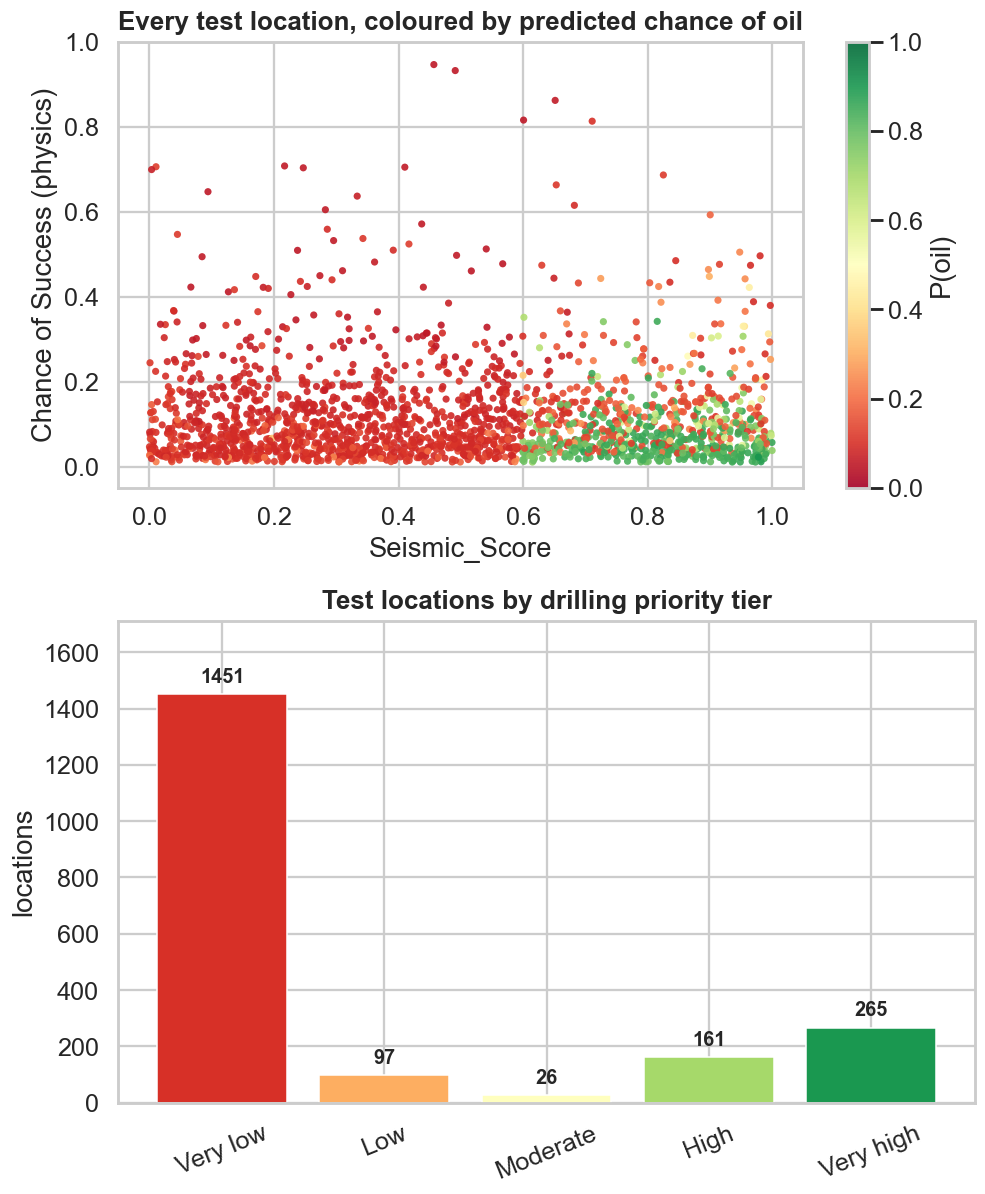

Risk_Tier
Very low     1451
Low            97
Moderate       26
High          161
Very high     265
Name: test locations, dtype: int64

In [ ]:
# Turn the Part 2 probabilities into a simple drilling priority view for the test set.
risk = X2_test.copy()
risk["Probability_Oil"] = proba_test_p2
risk["Prediction"] = pred_test_p2
risk["Risk_Tier"] = pd.cut(
    risk["Probability_Oil"],
    bins=[0, 0.20, 0.40, 0.60, 0.80, 1.00],
    labels=["Very low", "Low", "Moderate", "High", "Very high"],
    include_lowest=True,
)

tier_order = ["Very low", "Low", "Moderate", "High", "Very high"]
tier_counts = risk["Risk_Tier"].value_counts().reindex(tier_order).fillna(0).astype(int)
tier_palette = {
    "Very low": "#d73027",
    "Low": "#fdae61",
    "Moderate": "#ffffbf",
    "High": "#a6d96a",
    "Very high": "#1a9850",
}

fig, axes = plt.subplots(2, 1, figsize=(9.3, 11.2), gridspec_kw={"height_ratios": [1, 1.08]})

scatter = axes[0].scatter(
    risk["Seismic_Score"],
    risk["Chance_of_Success"],
    c=risk["Probability_Oil"],
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    s=22,
    alpha=0.9,
    edgecolors="none",
)
axes[0].set_title("Every test location, coloured by predicted chance of oil", fontsize=17, pad=8)
axes[0].set_xlabel("Seismic_Score")
axes[0].set_ylabel("Chance of Success (physics)")
axes[0].set_xlim(-0.05, 1.05)
axes[0].set_ylim(-0.05, max(1.0, risk["Chance_of_Success"].max() * 1.05))
cbar = fig.colorbar(scatter, ax=axes[0])
cbar.set_label("P(oil)")

bars = axes[1].bar(
    tier_order,
    tier_counts.values,
    color=[tier_palette[t] for t in tier_order],
    edgecolor="white",
    linewidth=1.0,
)
axes[1].set_title("Test locations by drilling priority tier", fontsize=17, pad=8)
axes[1].set_ylabel("locations")
axes[1].set_ylim(0, max(tier_counts.max() * 1.18, 10))
axes[1].tick_params(axis="x", rotation=22)
for bar, value in zip(bars, tier_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value + max(tier_counts.max() * 0.02, 3),
        f"{value}",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=13,
    )

plt.tight_layout(h_pad=1.0)
plt.savefig("figures/14_risk_map.png", bbox_inches="tight")
plt.show()

display(tier_counts.rename("test locations"))

**Figure 14.** This is the drilling-priority view using the Part 2 approach. Each dot is a
test prospect: the x axis is seismic support, the y axis is the built Chance of Success score,
and the colour is the final Part 2 LightGBM probability of oil. The bar chart turns those probabilities
into practical priority tiers for a drilling shortlist.

## 5. Part 1 vs Part 2

Since seismic score was the most important feature, cross validation result was compared on both the full training and rows with seismic data.


In [ ]:
# Out of fold probabilities for both models on identical folds.
oof_compare_p1 = np.zeros(len(y))
oof_compare_p2 = np.zeros(len(y))

for train_idx, val_idx in CV.split(X1_train, y):
    # Part 1 ensemble
    m1 = build_ensemble()
    m1.fit(X1_train[P1_NUM + P1_CAT].iloc[train_idx], y[train_idx])
    oof_compare_p1[val_idx] = m1.predict_proba(X1_train[P1_NUM + P1_CAT].iloc[val_idx])[:, 1]

    # Part 2 LightGBM, with weights learned only from this fold's training rows
    ref = train_raw.iloc[train_idx]
    Xf_train = physics_features(train_raw.iloc[train_idx], ref)
    Xf_val = physics_features(train_raw.iloc[val_idx], ref)
    Xf_train["Rock_Type"] = Xf_train["Rock_Type"].astype("category")
    Xf_val["Rock_Type"] = Xf_val["Rock_Type"].astype("category")

    m2 = LGBMClassifier(n_estimators=161, learning_rate=0.020922479707239747, max_depth=26,
                        num_leaves=12, min_child_samples=13, random_state=RANDOM_STATE, verbose=-1)
    m2.fit(Xf_train, y[train_idx], categorical_feature=["Rock_Type"])
    oof_compare_p2[val_idx] = m2.predict_proba(Xf_val)[:, 1]

print("Done. Out of fold probabilities ready for both models.")

Done. Out of fold probabilities ready for both models.


In [ ]:
# Build the comparison table on the two populations we can score.
def summarise(proba, mask, label):
    pred = (proba[mask] > 0.5).astype(int)
    return {
        "where": label,
        "Accuracy": round(accuracy_score(y[mask], pred), 4),
        "Recall": round(recall_score(y[mask], pred), 4),
        "F1": round(f1_score(y[mask], pred), 4),
        "ROC-AUC": round(roc_auc_score(y[mask], proba[mask]), 4),
        "PR-AUC": round(average_precision_score(y[mask], proba[mask]), 4),
    }

all_rows = np.ones(len(y), dtype=bool)
rows = []
for proba, model in [(oof_compare_p1, "Part 1 ensemble"), (oof_compare_p2, "Part 2 LightGBM")]:
    rows.append({"model": model, **summarise(proba, all_rows, "full train")})
    rows.append({"model": model, **summarise(proba, has_seismic, "train with seismic")})

compare_table = pd.DataFrame(rows)
print("Five fold cross validation:")
compare_table

Five fold cross validation:


,model,where,Accuracy,Recall,F1,ROC-AUC,PR-AUC
0,Part 1 ensemble,full train,0.8117,0.5174,0.6041,0.8131,0.6826
1,Part 1 ensemble,train with seismic,0.8846,0.6822,0.7578,0.8291,0.7319
2,Part 2 LightGBM,full train,0.8183,0.4682,0.5887,0.8257,0.6927
3,Part 2 LightGBM,train with seismic,0.8903,0.6977,0.7709,0.8356,0.7285


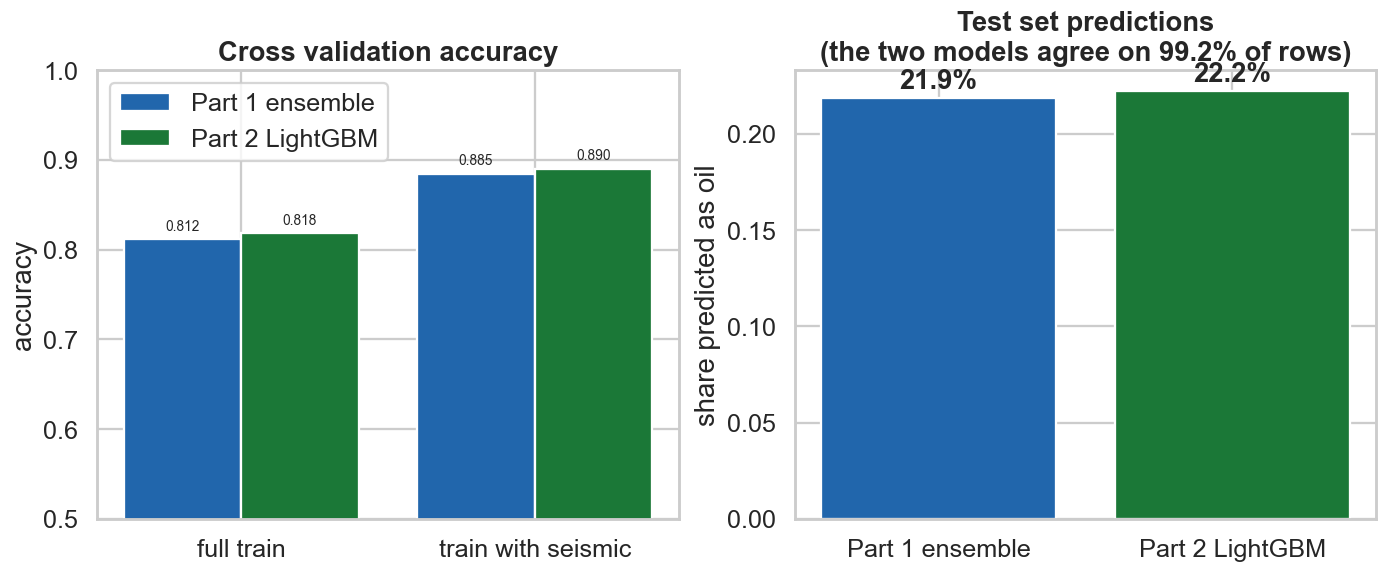

In [ ]:
# Predict the test set with both models and compare what they say (no answer key on test).
test_pred_p1 = (proba_test_p1 > 0.5).astype(int)
test_pred_p2 = (proba_test_p2 > 0.5).astype(int)
agreement = (test_pred_p1 == test_pred_p2).mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.3))

# left: bars of accuracy on the two scoreable populations, both models side by side
labels = ["full train", "train with seismic"]
p1_acc = [accuracy_score(y, (oof_compare_p1 > 0.5).astype(int)),
          accuracy_score(y[has_seismic], (oof_compare_p1[has_seismic] > 0.5).astype(int))]
p2_acc = [accuracy_score(y, (oof_compare_p2 > 0.5).astype(int)),
          accuracy_score(y[has_seismic], (oof_compare_p2[has_seismic] > 0.5).astype(int))]

x = np.arange(len(labels))
ax[0].bar(x - 0.2, p1_acc, 0.4, label="Part 1 ensemble", color=BLUE)
ax[0].bar(x + 0.2, p2_acc, 0.4, label="Part 2 LightGBM", color=GREEN)
ax[0].set_xticks(x)
ax[0].set_xticklabels(labels)
ax[0].set_ylim(0.5, 1.0)
ax[0].set_ylabel("accuracy")
ax[0].set_title("Cross validation accuracy")
ax[0].legend()
for xi, (a, b) in enumerate(zip(p1_acc, p2_acc)):
    ax[0].text(xi - 0.2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
    ax[0].text(xi + 0.2, b + 0.01, f"{b:.3f}", ha="center", fontsize=9)

# right: predicted oil rate on the test set (no truth available)
ax[1].bar(["Part 1 ensemble", "Part 2 LightGBM"],
          [test_pred_p1.mean(), test_pred_p2.mean()], color=[BLUE, GREEN])
ax[1].set_ylabel("share predicted as oil")
ax[1].set_title(f"Test set predictions\n(the two models agree on {agreement:.1%} of rows)")
for i, v in enumerate([test_pred_p1.mean(), test_pred_p2.mean()]):
    ax[1].text(i, v + 0.005, f"{v:.1%}", ha="center", fontweight="bold")

plt.savefig("figures/15_part1_vs_part2.png", bbox_inches="tight")
plt.show()

**Figure 15.**  Although the two models were different, they returned close values.
On the test set, they predict similar classes and agree on a vast majority of rows.

## 6. Conclusion

Both model approaches returned good results. However, the single physics informed LightGBM model performed better than the ensemble model and was consistent with petroleum goescience principles. This reinforces the place of domain knowledge as the indutry seeks to enhance the integration of artificial intelligence.

